## Crop Recommendation Prediction

### 1.Imoprt Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
import joblib
import os

### 2.Read Data

In [2]:
df = pd.read_csv('E:/Projects/AgriMind-AI/Data/Crop Recommendation Dataset/Crop_recommendation.csv')

#### 3.Explore Dataset

In [3]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
df.shape

(2200, 8)

In [5]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


### 4. Data Quality Assessment

In [7]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

### 5. Target Distribution Analysis

In [9]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [10]:
df['label'].unique()

<StringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str

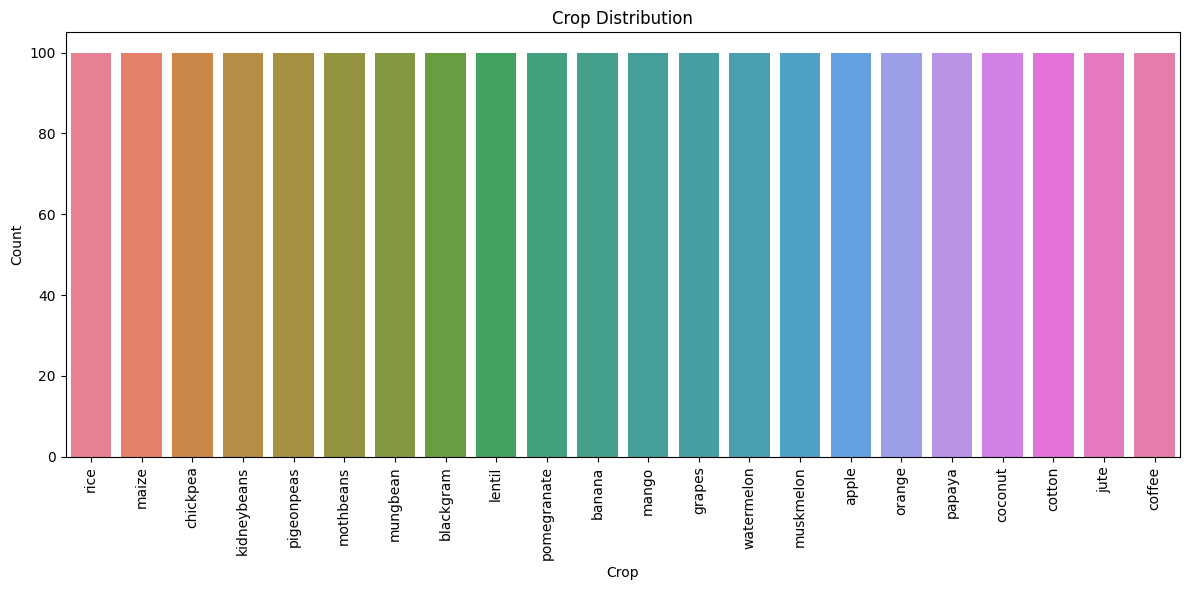

In [11]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x="label", hue="label", legend=False)

plt.xticks(rotation=90)
plt.title("Crop Distribution")
plt.xlabel("Crop")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### 6. Numerical Features Distribution

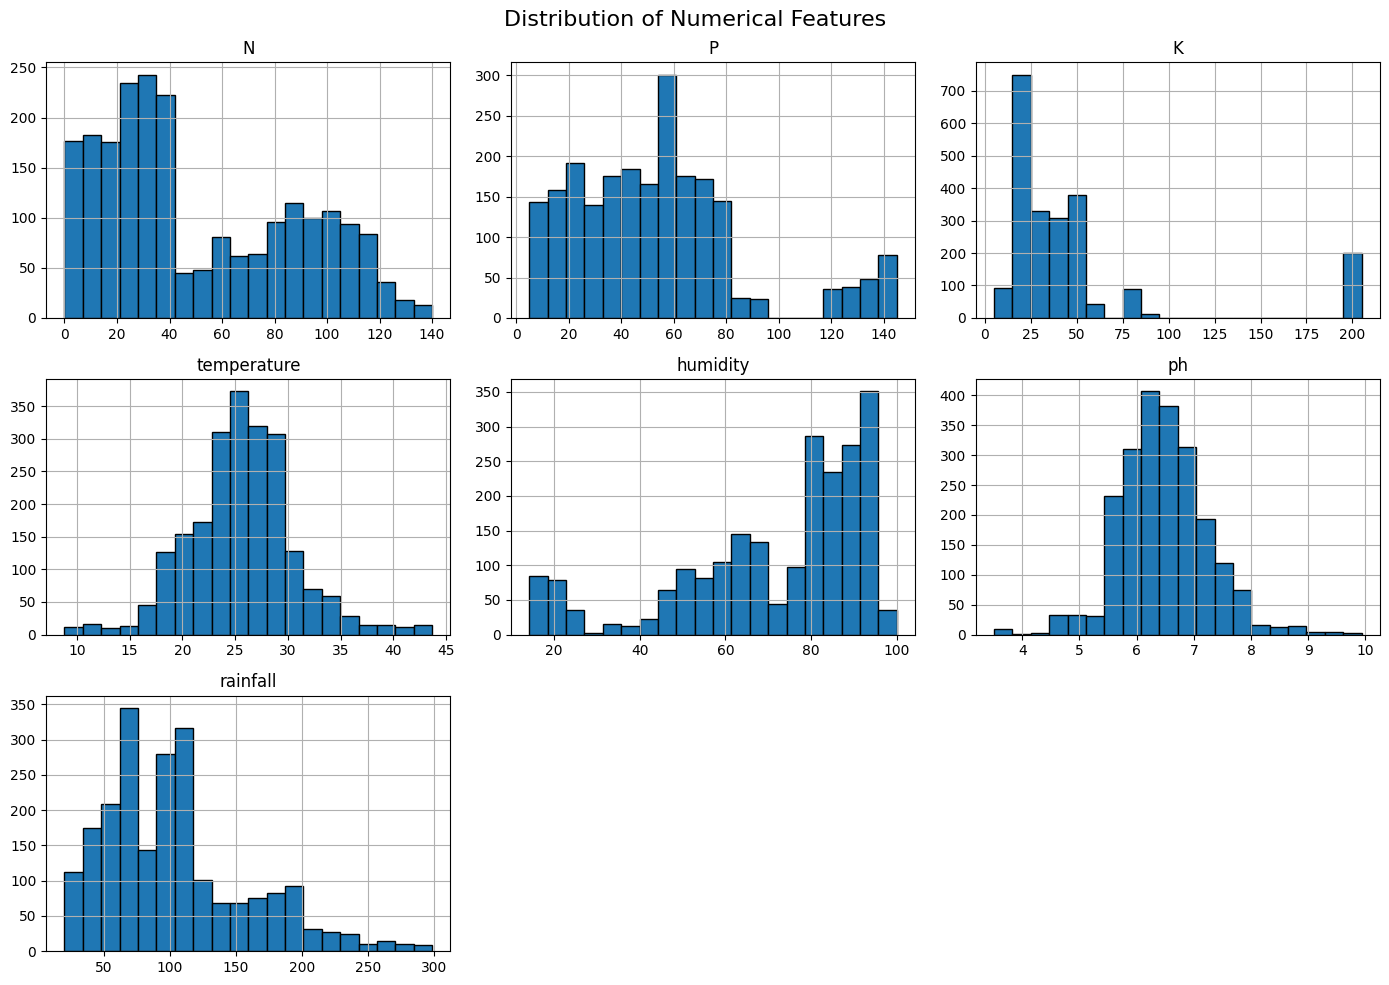

In [12]:
numerical_features = df.select_dtypes(include="number").columns

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### 7. Outlier Detection

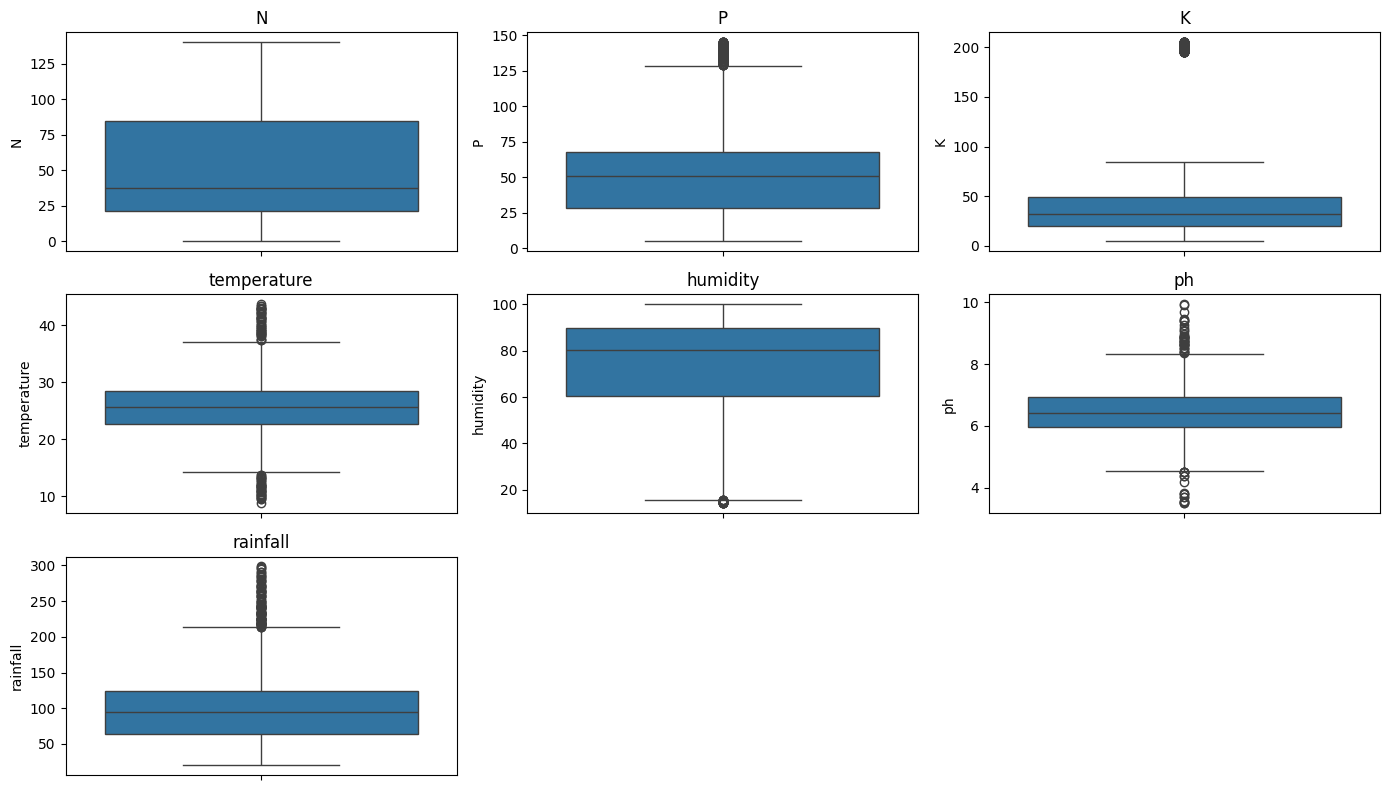

In [13]:
numerical_features = df.select_dtypes(include="number").columns

plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [14]:
for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

N: 0 outliers
P: 138 outliers
K: 200 outliers
temperature: 86 outliers
humidity: 30 outliers
ph: 57 outliers
rainfall: 100 outliers


### 8. Feature Range Validation

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


In [16]:
df.groupby("label")[
    ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
].mean().round(2)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79


### 8. Exploratory Data Analysis (EDA)


#### 8.1 Correlation Analysis

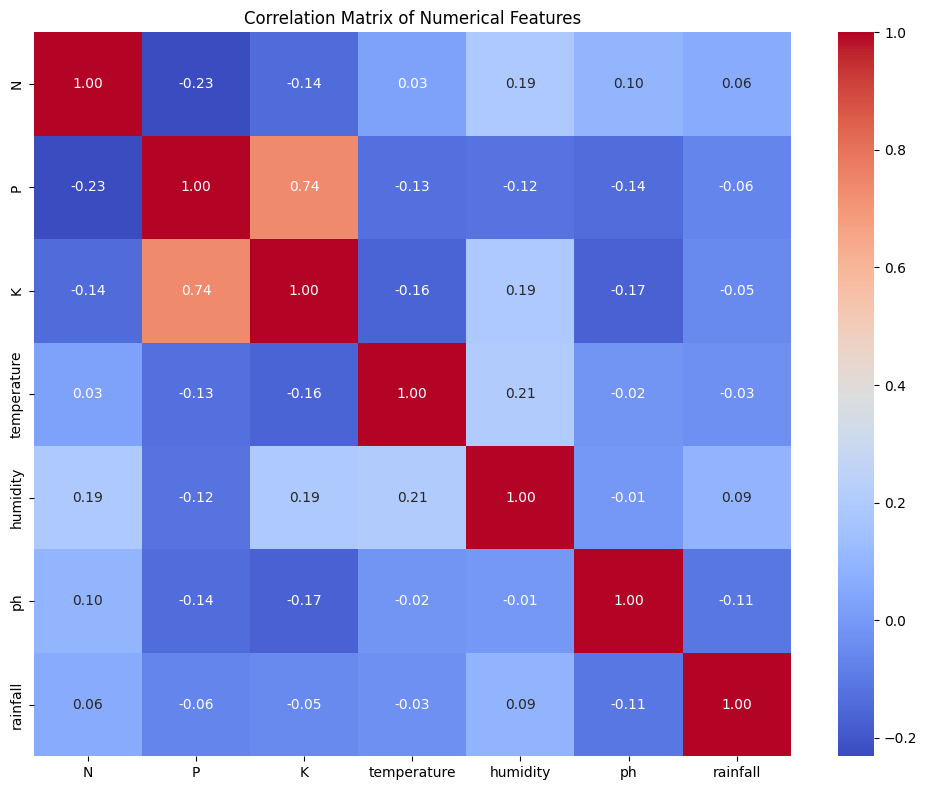

In [17]:
plt.figure(figsize=(10, 8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

#### 8.2 Feature Distribution Across Crops

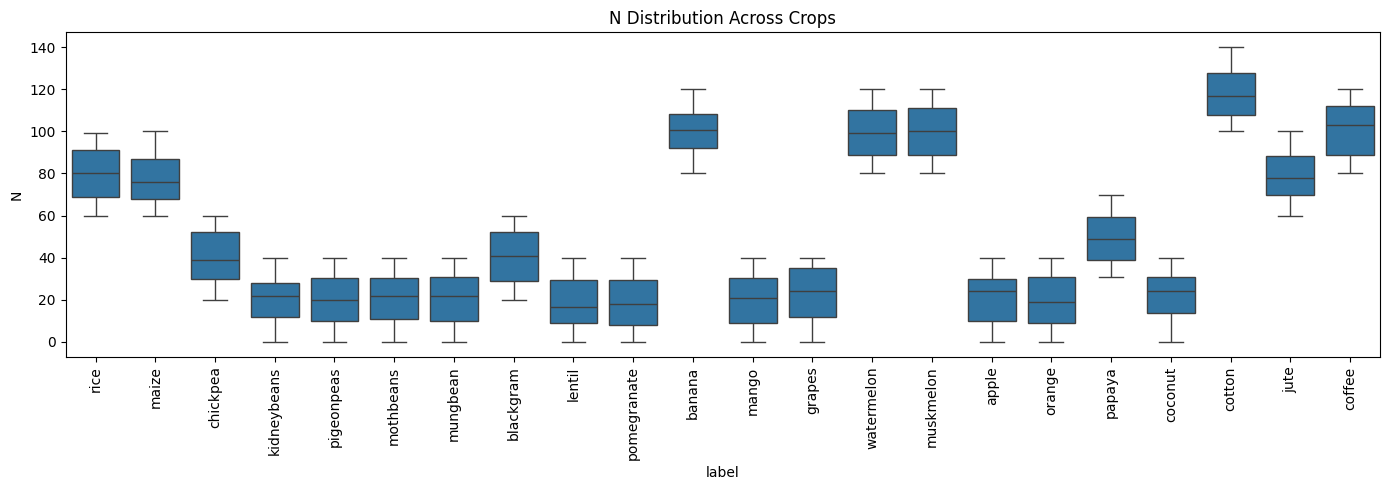

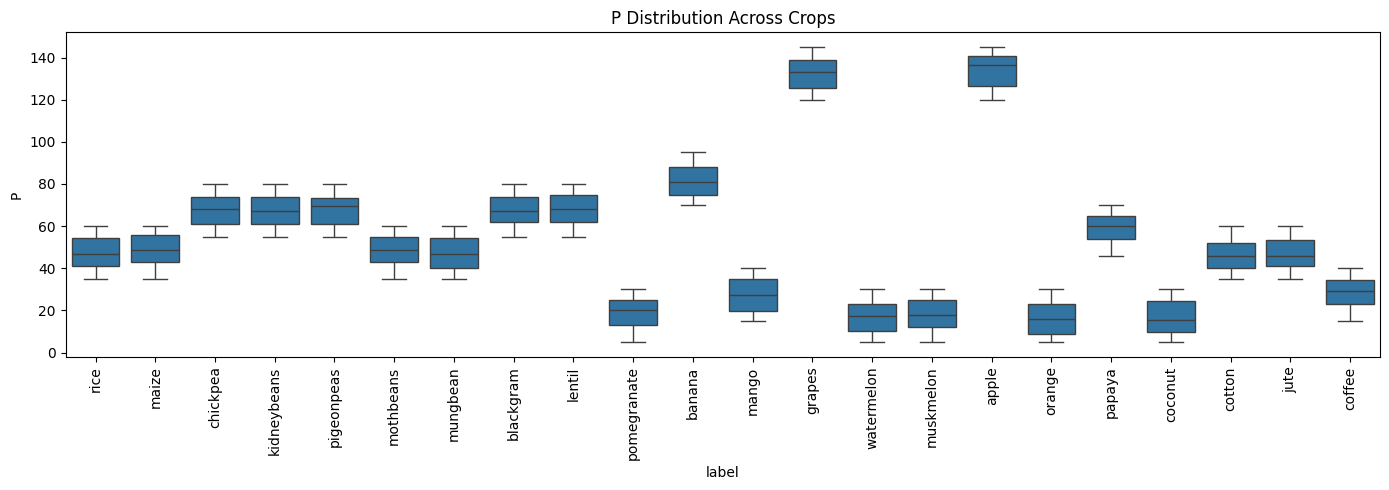

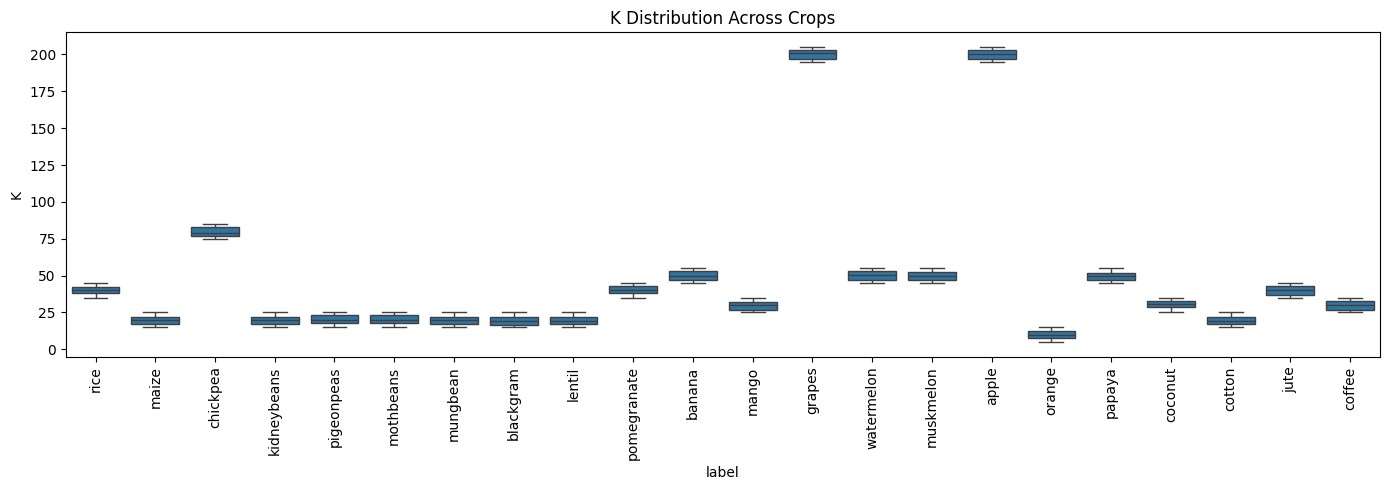

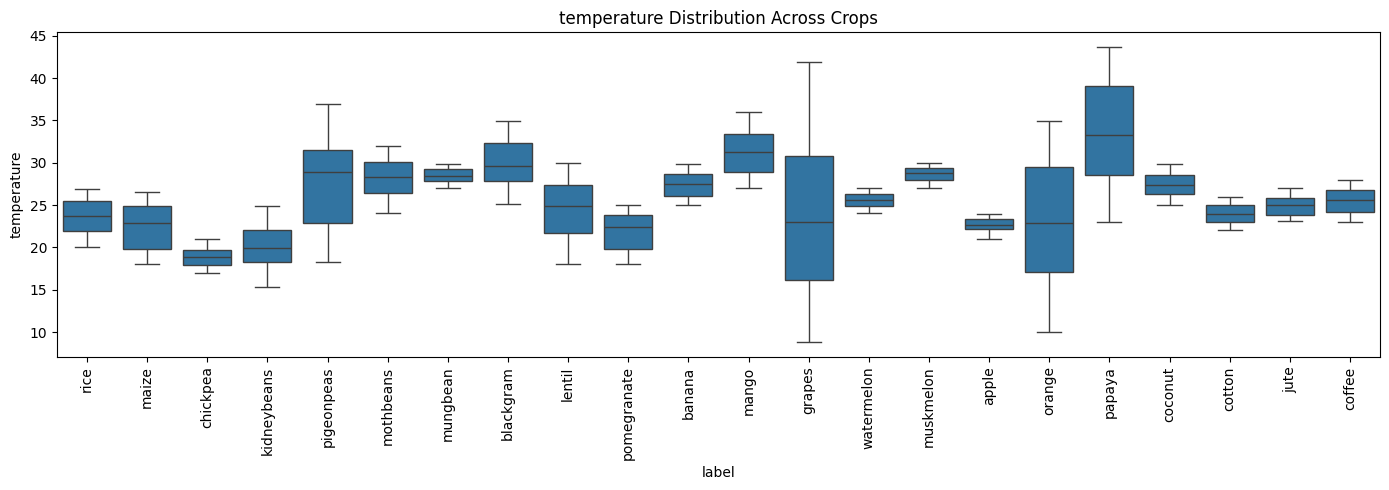

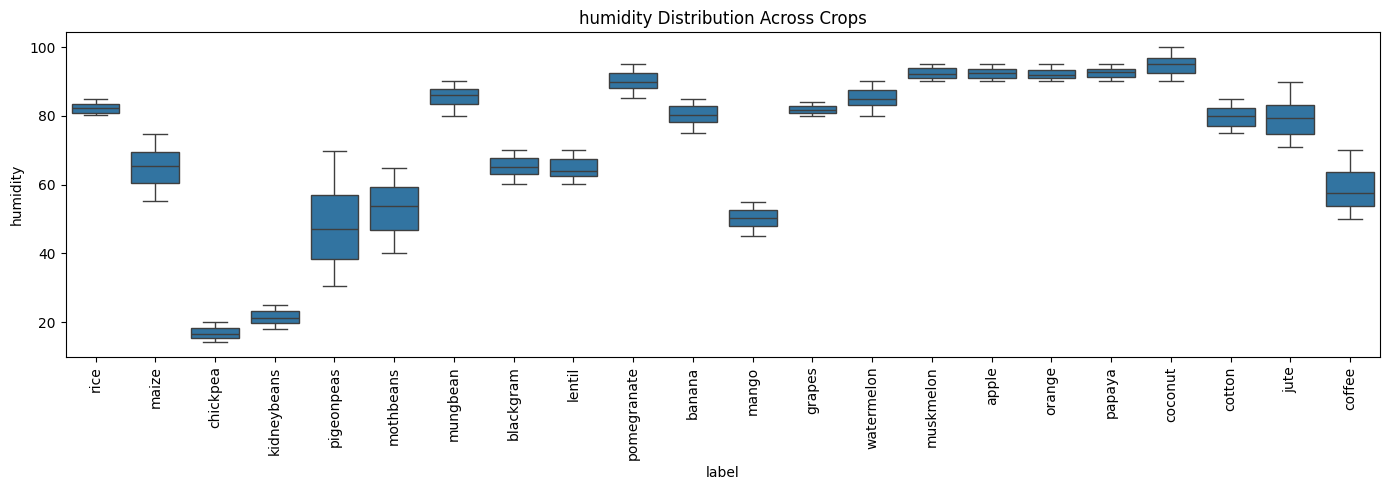

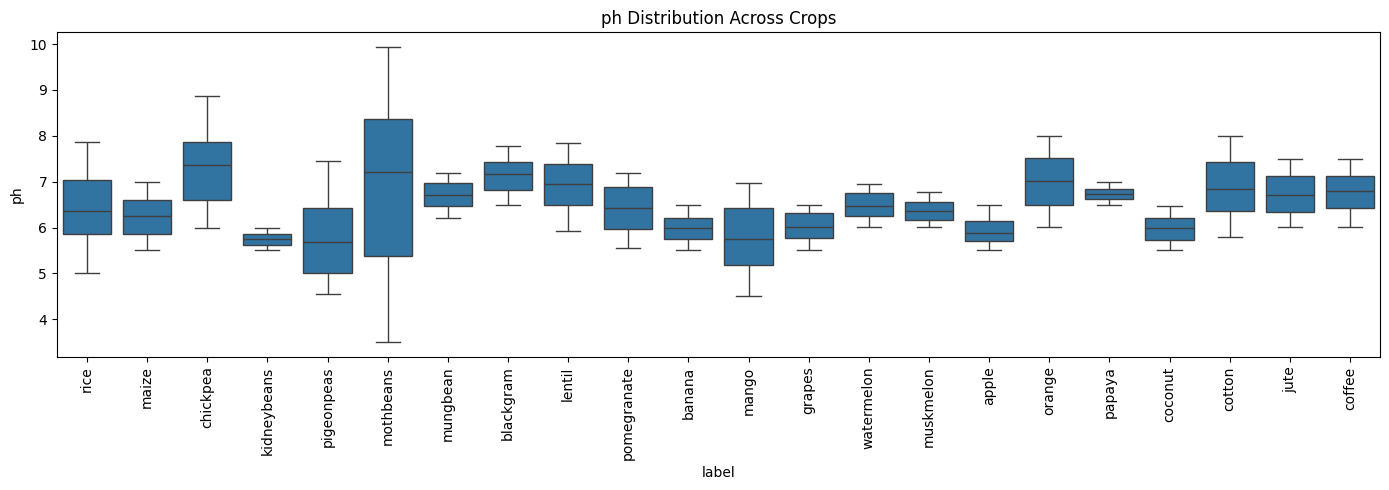

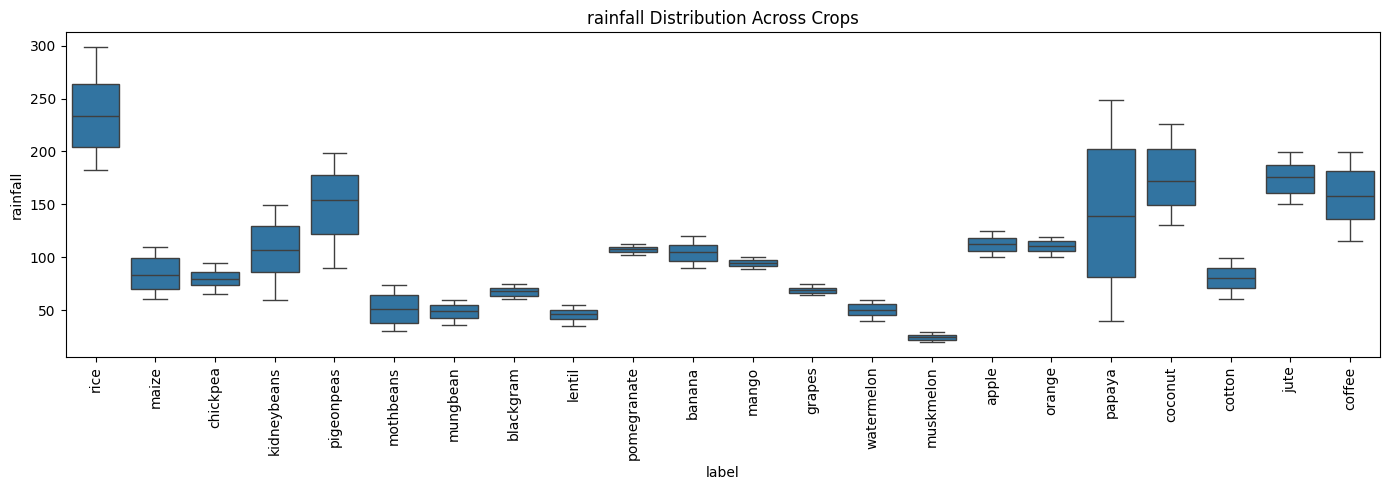

In [18]:
features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

for col in features:
    plt.figure(figsize=(14, 5))

    sns.boxplot(data=df, x="label", y=col)

    plt.title(f"{col} Distribution Across Crops")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

#### 8.3 Feature Relationships

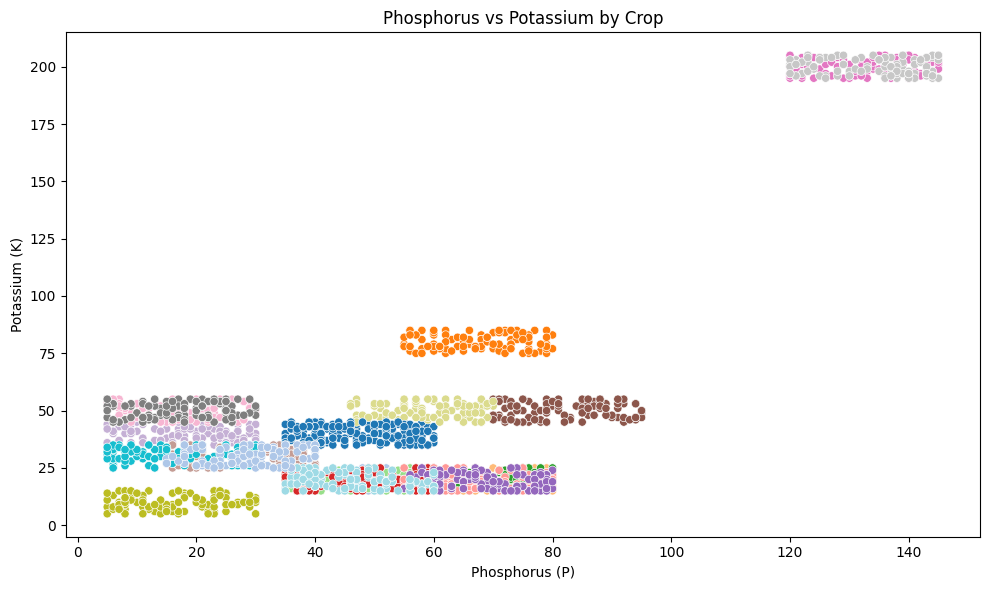

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="P",
    y="K",
    hue="label",
    palette="tab20",
    legend=False
)

plt.title("Phosphorus vs Potassium by Crop")
plt.xlabel("Phosphorus (P)")
plt.ylabel("Potassium (K)")

plt.tight_layout()
plt.show()

### 9. Data Preprocessing


### 9.1 Separate Features and Target

In [20]:
X = df.drop("label", axis=1)
y = df["label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2200, 7)
Target shape: (2200,)


### 10.Train-Test Split

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1760, 7)
X_test: (440, 7)
y_train: (1760,)
y_test: (440,)


### 11. Model Training 

#### 11.1 Decision Tree Classifier

In [23]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9795454545454545
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        2

#### 11.2 Random Forest Classifier

In [24]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.9954545454545455
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        2

#### 11.3 Model Comparison

In [25]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro")
    ]
})

results = results.sort_values(by="Accuracy", ascending=False)
results

,Model,Accuracy,Macro F1
1,Random Forest,0.995455,0.995452
0,Decision Tree,0.979545,0.979423


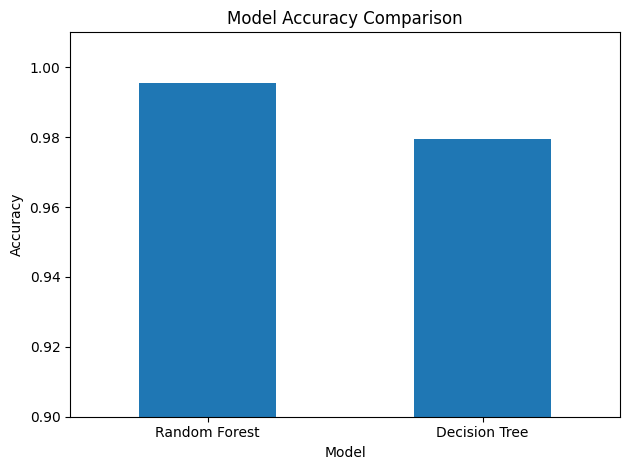

In [26]:
results.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    ylim=(0.90, 1.01),
    title="Model Accuracy Comparison",
    ylabel="Accuracy",
    rot=0
)

plt.tight_layout()
plt.show()

#### 11.4 Cross-Validation

In [27]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores: [1.         0.99715909 0.98295455 0.99147727 0.99715909]
Mean Accuracy: 0.99375
Standard Deviation: 0.006066521734108723


### 12. Final Model Evaluation


### 12.1 Confusion Matrix

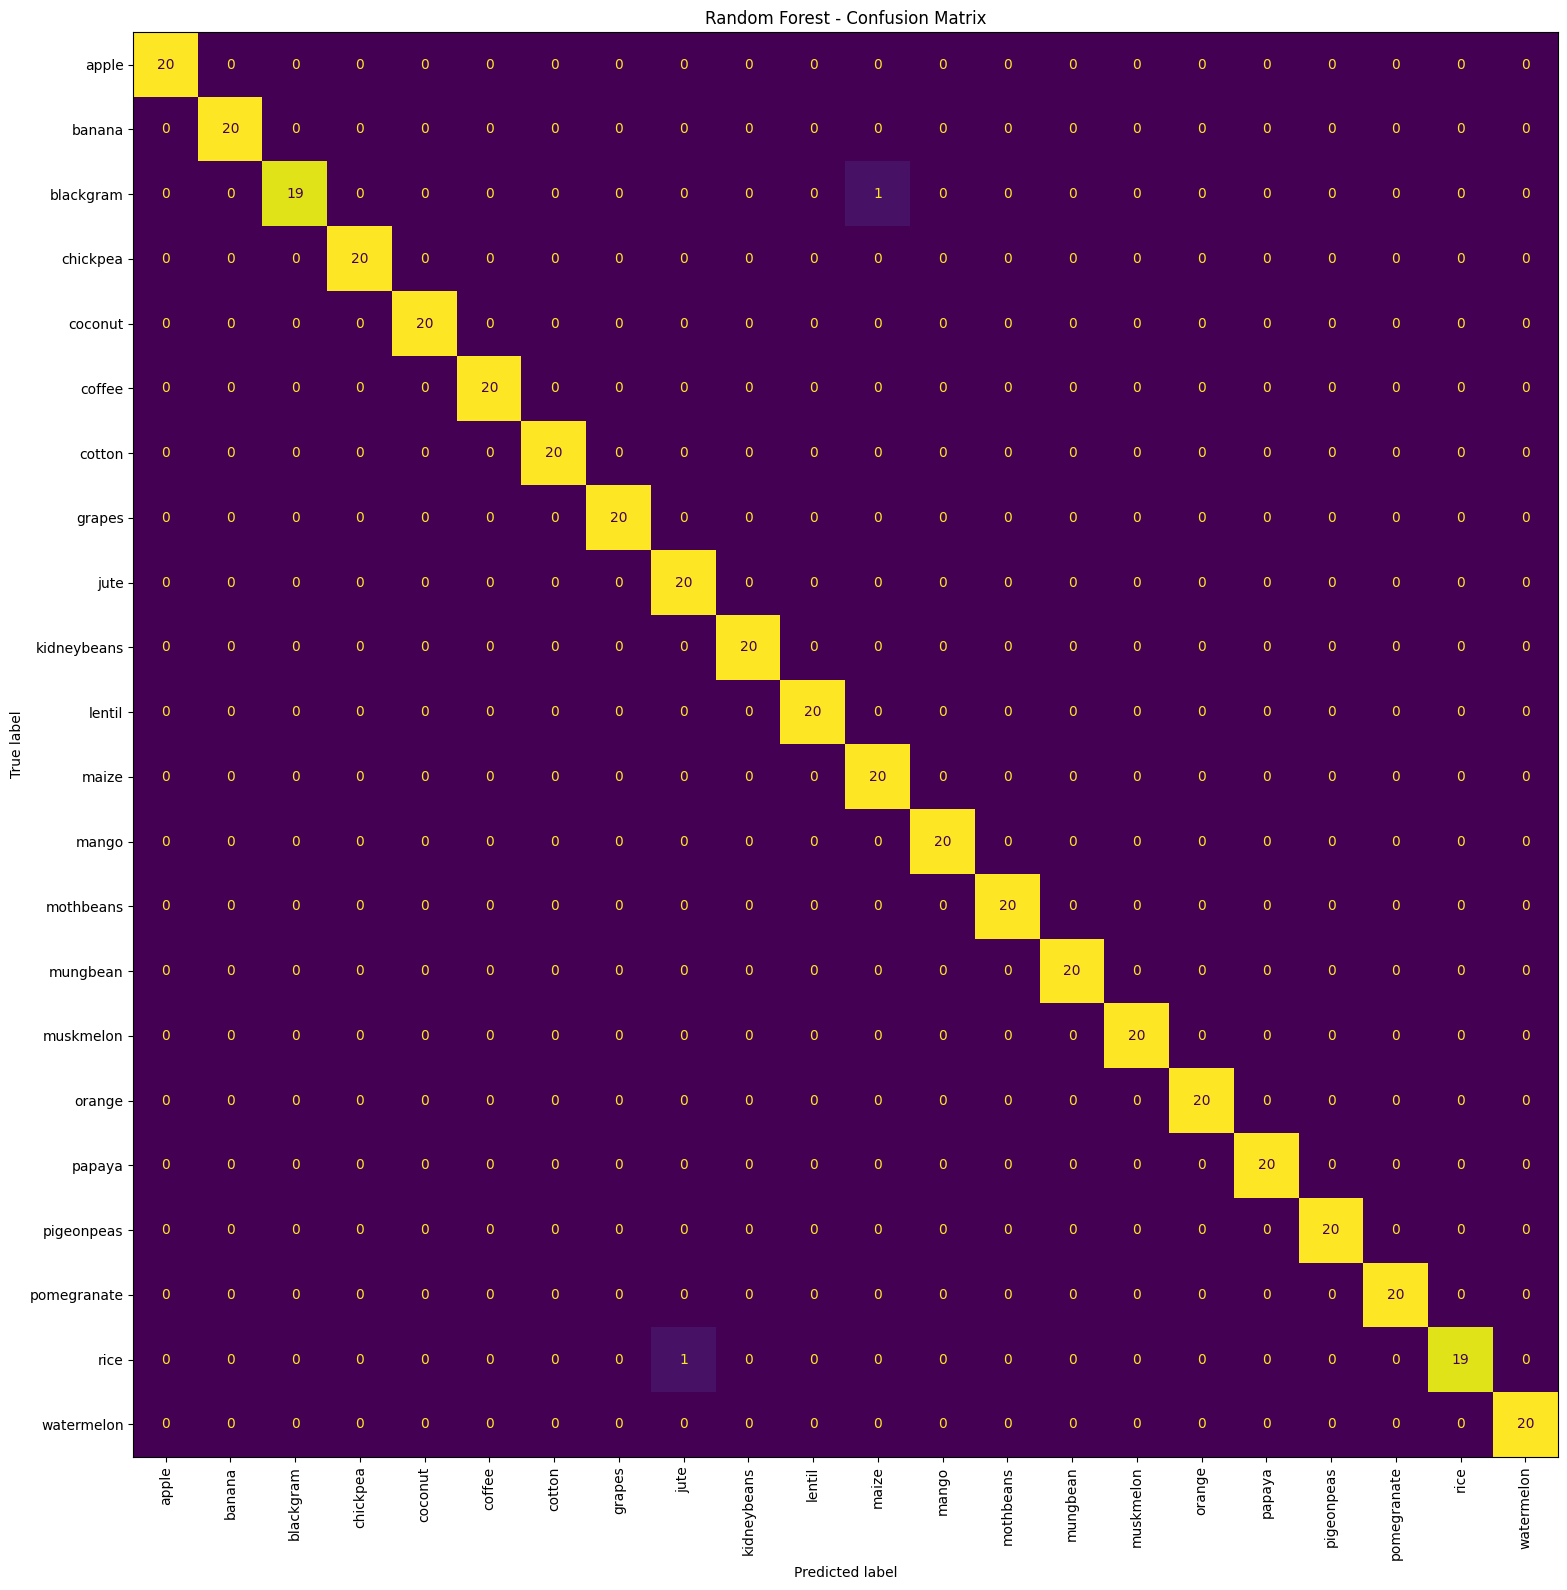

In [28]:
y_pred_rf = rf_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

fig, ax = plt.subplots(figsize=(16, 16))
disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
cm

array([[20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0, 19,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 20,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0, 20,  0,  0,

#### 12.2 Misclassified Samples

In [30]:
misclassified = X_test[y_test != y_pred_rf].copy()

misclassified["Actual"] = y_test[y_test != y_pred_rf]
misclassified["Predicted"] = y_pred_rf[y_test != y_pred_rf]

misclassified

,N,P,K,temperature,humidity,ph,rainfall,Actual,Predicted
789,60,59,22,31.868473,66.742175,7.191523,74.222386,blackgram,maize
83,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute


## 13. Conclusion

- The dataset contains 2,200 records, 7 numerical features, and 22 crop classes.
- No missing values or duplicate records were found.
- Exploratory Data Analysis revealed differences in numerical feature distributions and a positive correlation between phosphorus (P) and potassium (K).
- Two classification models were evaluated: Decision Tree and Random Forest.
- Random Forest achieved the best test accuracy of 99.55% and a macro F1-score of approximately 99.55%.
- Five-fold stratified cross-validation achieved a mean accuracy of 99.375%.
- The final test evaluation identified only two misclassified samples out of 440.
- Further evaluation on independent, real-world agricultural data is recommended before deployment.

## 14. Save Best Model

In [31]:
os.makedirs("../Models", exist_ok=True)

joblib.dump(
    rf_model,
    "../Models/crop_recommendation_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


### 15. Load Saved Model & Make Prediction

In [32]:
loaded_model = joblib.load(
    "../Models/crop_recommendation_model.pkl"
)

sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25,
    "humidity": 80,
    "ph": 6.5,
    "rainfall": 200
}])

prediction = loaded_model.predict(sample)

print("Recommended Crop:", prediction[0])

Recommended Crop: rice
